# SynthHeart · 01 · Prepare the data and measure the real baseline

**Goal of this notebook**
1. Load the Kaggle cardiovascular dataset (`data/cardio_train.csv`).
2. Clean it with medical-range rules (the same rules later filter the synthetic patients).
3. Split the real patients into **train 60% / holdout 20% / test 20%**, stratified on the label.
4. Write the files the bootcamp's TabDDPM pipeline (midst-toolkit) expects: `cardio.csv`, `cardio_domain.json`, `dataset_meta.json`, `meta_info.json`.
5. Train the **real baseline** (TRTR: train on real, test on real). This is the score the synthetic data has to match.

**Outputs**
- `implementations/synthheart/data/cardio/`: splits + metadata. CSVs are git-ignored, so re-run this notebook to recreate them.
- `implementations/synthheart/results/baseline_metrics.json`: committed, so the team shares one baseline.

Runs on CPU in about a minute. No GPU needed.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# Make the shared helpers importable no matter where Jupyter was started.
here = Path.cwd().resolve()
project = next(p / "implementations" / "synthheart" for p in [here, *here.parents]
               if (p / "implementations" / "synthheart" / "synthheart_common.py").exists())
sys.path.insert(0, str(project))

import synthheart_common as sh

np.random.seed(sh.SEED)
print("repo:", sh.REPO)
print("raw data:", sh.RAW_CSV, "| exists:", sh.RAW_CSV.exists())

repo: /home/jovyan/berka-saif/Cardio_telus_2/synthetic-data-bootcamp-telus-2
raw data: /home/jovyan/berka-saif/Cardio_telus_2/synthetic-data-bootcamp-telus-2/data/cardio_train.csv | exists: True


## 1 · Load the raw data

In [2]:
raw = sh.load_raw()
print(raw.shape)
raw.head()

(70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [3]:
print("missing values:", int(raw.isna().sum().sum()))
print("duplicate rows (ignoring id):", int(raw.drop(columns="id").duplicated().sum()))
print("label balance:", raw["cardio"].value_counts(normalize=True).round(3).to_dict())
raw.describe().T.round(1)

missing values: 0
duplicate rows (ignoring id): 24
label balance: {0: 0.5, 1: 0.5}


,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.4,28851.3,0.0,25006.8,50001.5,74889.2,99999.0
age,70000.0,19468.9,2467.3,10798.0,17664.0,19703.0,21327.0,23713.0
gender,70000.0,1.3,0.5,1.0,1.0,1.0,2.0,2.0
height,70000.0,164.4,8.2,55.0,159.0,165.0,170.0,250.0
weight,70000.0,74.2,14.4,10.0,65.0,72.0,82.0,200.0
ap_hi,70000.0,128.8,154.0,-150.0,120.0,120.0,140.0,16020.0
ap_lo,70000.0,96.6,188.5,-70.0,80.0,80.0,90.0,11000.0
cholesterol,70000.0,1.4,0.7,1.0,1.0,1.0,2.0,3.0
gluc,70000.0,1.2,0.6,1.0,1.0,1.0,1.0,3.0
smoke,70000.0,0.1,0.3,0.0,0.0,0.0,0.0,1.0


## 2 · Clean with medical-range rules

Blood pressure has obvious entry errors (systolic from −150 to 16020, diastolic up to 11000). We **drop** rows that break a rule rather than guessing a fix. The same rules live in `synthheart_common.py` and are reused to filter synthetic patients.

In [4]:
df = sh.to_model_format(raw)          # age -> years, 0-based categories, fixed column order
clean, fails = sh.apply_rules(df)

print("rows failing each rule:")
print(fails[fails > 0].to_string())
print(f"\nremoved {len(df) - len(clean):,} of {len(df):,} rows ({1 - len(clean) / len(df):.1%}) -> {len(clean):,} kept")
print("label balance after cleaning:", clean["cardio"].value_counts(normalize=True).round(3).to_dict())

rows failing each rule:
height outside 130-210      93
weight outside 35-200       20
ap_hi outside 80-250       247
ap_lo outside 40-160      1025
ap_hi <= ap_lo            1236

removed 1,441 of 70,000 rows (2.1%) -> 68,559 kept
label balance after cleaning: {0: 0.505, 1: 0.495}


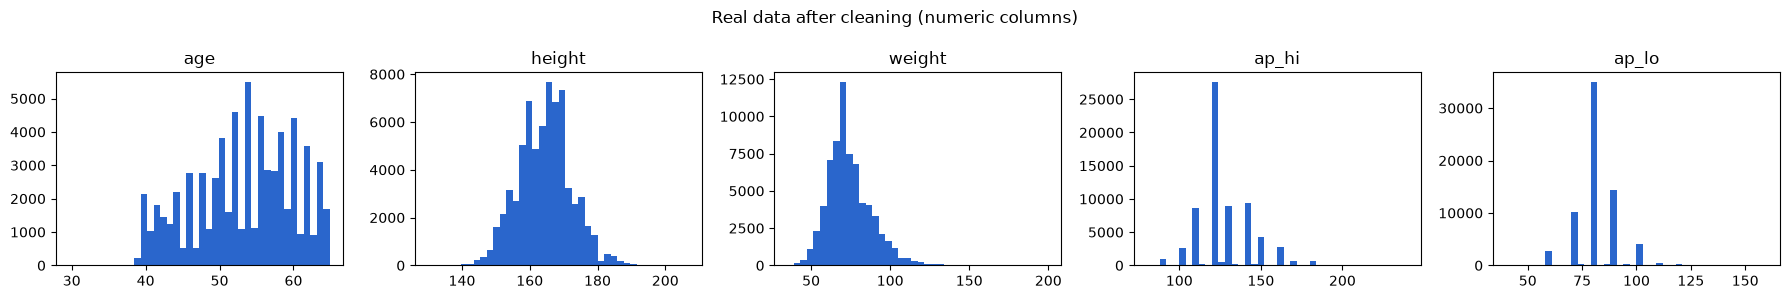

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, col in zip(axes, sh.NUM_COLS):
    ax.hist(clean[col], bins=40, color="#2a66cc")
    ax.set_title(col)
fig.suptitle("Real data after cleaning (numeric columns)")
plt.tight_layout()
plt.show()

## 3 · Split: train 60% / holdout 20% / test 20%

- **train**: the only real data the generator (TabDDPM) ever sees.
- **holdout**: never used for training; the privacy metrics compare "closer to train than to holdout?".
- **test**: the locked final exam. Every model, real-trained or synthetic-trained, is scored here and nowhere else.

In [6]:
train, rest = train_test_split(clean, test_size=0.4, stratify=clean[sh.TARGET], random_state=sh.SEED)
holdout, test = train_test_split(rest, test_size=0.5, stratify=rest[sh.TARGET], random_state=sh.SEED)

for name, part in [("train", train), ("holdout", holdout), ("test", test)]:
    print(f"{name:8s} {len(part):6,d} rows | cardio=1: {part[sh.TARGET].mean():.3f}")

train    41,135 rows | cardio=1: 0.495
holdout  13,712 rows | cardio=1: 0.495
test     13,712 rows | cardio=1: 0.495


## 4 · Write files in the midst-toolkit format

Same shape as the bootcamp's Berka example in `implementations/tabular_data/single_table/data/`.

In [7]:
sh.DATA_DIR.mkdir(parents=True, exist_ok=True)
train.to_csv(sh.DATA_DIR / f"{sh.TABLE}.csv", index=False)
holdout.to_csv(sh.DATA_DIR / f"{sh.TABLE}_holdout.csv", index=False)
test.to_csv(sh.DATA_DIR / f"{sh.TABLE}_test.csv", index=False)

domain = {c: {"type": "continuous" if c in sh.NUM_COLS else "discrete"} for c in sh.ALL_COLS}
dataset_meta = {"relation_order": [[None, sh.TABLE]], "tables": {sh.TABLE: {"children": [], "parents": []}}}
meta_info = {
    "num_col_idx": [sh.ALL_COLS.index(c) for c in sh.NUM_COLS],
    "cat_col_idx": [sh.ALL_COLS.index(c) for c in sh.CAT_COLS],
    "target_col_idx": [sh.ALL_COLS.index(sh.TARGET)],
    # midst-toolkit TaskType.BINARY_CLASSIFICATION (0/1 label)
    "task_type": "binclass",
}
for name, obj in [(f"{sh.TABLE}_domain.json", domain), ("dataset_meta.json", dataset_meta), ("meta_info.json", meta_info)]:
    (sh.DATA_DIR / name).write_text(json.dumps(obj, indent=2))

print("written to", sh.DATA_DIR)
for p in sorted(sh.DATA_DIR.iterdir()):
    print(f"  {p.name:22s} {p.stat().st_size / 1024:8.1f} KB")
print(json.dumps(meta_info, indent=2))

written to /home/jovyan/berka-saif/Cardio_telus_2/synthetic-data-bootcamp-telus-2/implementations/synthheart/data/cardio
  cardio.csv               1410.4 KB
  cardio_domain.json          0.5 KB
  cardio_holdout.csv        470.1 KB
  cardio_test.csv           470.2 KB
  dataset_meta.json           0.1 KB
  meta_info.json              0.2 KB
{
  "num_col_idx": [
    0,
    1,
    2,
    3,
    4
  ],
  "cat_col_idx": [
    5,
    6,
    7,
    8,
    9,
    10,
    11
  ],
  "target_col_idx": [
    11
  ],
  "task_type": "binclass"
}


## 5 · The real baseline (TRTR)

Train on the **real train split**, score on the **locked test split**. BMI is added as a derived feature (`weight / height²`). It is never generated.

**Sanity check:** published results on this dataset sit around **0.79–0.80 AUC / ~73% accuracy**. Far higher would mean something is leaking.

In [8]:
X_tr, y_tr = sh.xy(train)
X_te, y_te = sh.xy(test)

models = {
    "xgboost": XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="logloss", random_state=sh.SEED, n_jobs=-1),
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
}
baseline = {}
for name, model in models.items():
    cv_auc = cross_val_score(model, X_tr, y_tr, cv=StratifiedKFold(5, shuffle=True, random_state=sh.SEED), scoring="roc_auc")
    model.fit(X_tr, y_tr)
    proba = model.predict_proba(X_te)[:, 1]
    baseline[name] = {
        "test_auc": round(float(roc_auc_score(y_te, proba)), 4),
        "test_accuracy": round(float(accuracy_score(y_te, proba >= 0.5)), 4),
        "cv_auc_mean": round(float(cv_auc.mean()), 4),
        "cv_auc_std": round(float(cv_auc.std()), 4),
    }
    print(f"{name:8s} test AUC {baseline[name]['test_auc']:.4f} | accuracy {baseline[name]['test_accuracy']:.4f} "
          f"| 5-fold CV AUC {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")

xgboost  test AUC 0.8014 | accuracy 0.7366 | 5-fold CV AUC 0.8002 ± 0.0056


logreg   test AUC 0.7913 | accuracy 0.7277 | 5-fold CV AUC 0.7909 ± 0.0056


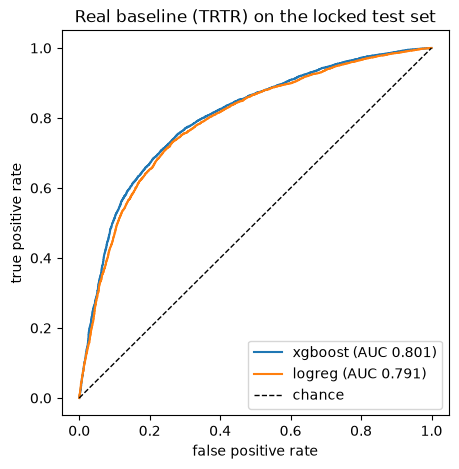

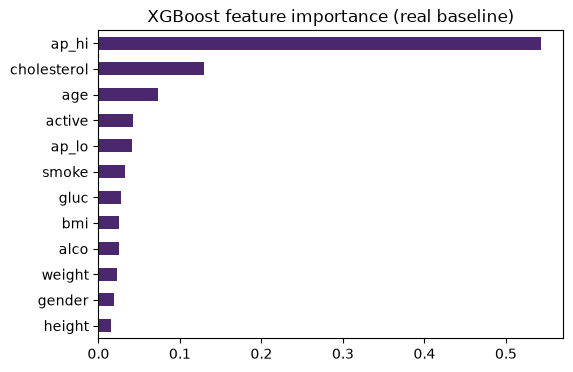

In [9]:
fig, ax = plt.subplots(figsize=(5, 5))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_te, model.predict_proba(X_te)[:, 1])
    ax.plot(fpr, tpr, label=f"{name} (AUC {baseline[name]['test_auc']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("Real baseline (TRTR) on the locked test set")
ax.legend()
plt.show()

imp = pd.Series(models["xgboost"].feature_importances_, index=X_tr.columns).sort_values()
imp.plot.barh(figsize=(6, 4), color="#4B286D", title="XGBoost feature importance (real baseline)")
plt.show()

## 6 · Save the baseline for the team

In [10]:
sh.RESULTS_DIR.mkdir(parents=True, exist_ok=True)
summary = {
    "rows_raw": int(len(raw)),
    "rows_clean": int(len(clean)),
    "split_rows": {"train": int(len(train)), "holdout": int(len(holdout)), "test": int(len(test))},
    "rules_failed": {k: int(v) for k, v in fails[fails > 0].items()},
    "trtr_baseline": baseline,
    "acceptance_target": "synthetic-trained (TSTR) AUC within 0.02 of the xgboost TRTR test AUC",
}
(sh.RESULTS_DIR / "baseline_metrics.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "rows_raw": 70000,
  "rows_clean": 68559,
  "split_rows": {
    "train": 41135,
    "holdout": 13712,
    "test": 13712
  },
  "rules_failed": {
    "height outside 130-210": 93,
    "weight outside 35-200": 20,
    "ap_hi outside 80-250": 247,
    "ap_lo outside 40-160": 1025,
    "ap_hi <= ap_lo": 1236
  },
  "trtr_baseline": {
    "xgboost": {
      "test_auc": 0.8014,
      "test_accuracy": 0.7366,
      "cv_auc_mean": 0.8002,
      "cv_auc_std": 0.0056
    },
    "logreg": {
      "test_auc": 0.7913,
      "test_accuracy": 0.7277,
      "cv_auc_mean": 0.7909,
      "cv_auc_std": 0.0056
    }
  },
  "acceptance_target": "synthetic-trained (TSTR) AUC within 0.02 of the xgboost TRTR test AUC"
}


## Next

- **02 · Train TabDDPM** (GPU, AI Factory): fit the bootcamp's single-table TabDDPM on `data/cardio/cardio.csv`, then sample synthetic patients.
- **03 · Scorecard**: filter the synthetic rows with `sh.apply_rules`, then fidelity, utility (TSTR vs the baseline above) and privacy.